# 04 · Pupil and locomotion state under each baseline

These are the old pupil analyses (zero-lag correlation maps, pupil diameter/derivative lag curves, ΔF/F tuning by pupil size), plus the locomotion analysis Sarah asked about. Each is redrawn under every baseline definition in `SPEC`.

- **Pupil**: non-positive and missing values are excluded. Lag curves use a Savitzky–Golay smoothed pupil and its derivative within continuous valid segments, never across gaps. Positive lag means fluorescence follows pupil.
- **Running**: frames count as running when speed is above `RUNNING_MODEL.threshold` for at least `min_bout_s`. The speed histogram is there to sanity-check the threshold, which is in the table's speed units. The run-onset analysis aligns whole-FOV ΔF/F to transitions from stationary to running.
- **Regressing out running**: the pupil analyses are repeated on ΔF/F with a lagged linear running model regressed out, and again on stationary frames only. With `regress_running = True`, every section uses running-regressed ΔF/F. The comparison section always shows original, regressed and stationary-only side by side.
- All results are descriptive and within one recording. Consecutive frames are correlated, so no p-values are given. The old circular-shift significance test still runs on the exports (see NOTEBOOKS.md).

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from nlight import analyses, analysis_plots as ap, plotting, recording_comparison, regression, session, state

plotting.use_lab_style()
RECORDINGS = session.load_recordings(Path('../../configs/nlight_recordings.json'))
print('Available:', list(RECORDINGS))

Available: ['corridor2 passive viewing', 'corridor2 baseline', 'passive (4 planes)', 'no puff (2x, 4 planes)', 'puff (2x, 4 planes)']


In [ ]:
RECORDING = 'corridor2 passive viewing'   # any name from configs/nlight_recordings.json
# Baseline definitions applied to every analysis below. The first is the "current" method.
SPEC = recording_comparison.BaselineSpec(current_window_s=60, current_percentile=50,
                                         fixed_percentiles=(10,), long_windows_s=(180, 300, 600))
# True: every analysis below uses running-regressed ΔF/F (fitted per baseline method and per tile).
# The originals stay available as s['wf_original'] and each tile's 'dff_original'.
regress_running = True
# Running definition and regression model, shared by notebooks 02-04. threshold is in the
# behaviour table's speed units; check it against the speed histogram in notebook 04.
RUNNING_MODEL = regression.RunningModel(threshold=2.0, min_bout_s=1.0, min_lag_s=-1.0,
                                        max_lag_s=5.0, step_s=0.25, cv_folds=5, cv_gap_s=30.0)
MAX_LAG_S = 3.0
PUPIL_SMOOTHING_S = 0.5
N_BINS, MIN_BIN_SAMPLES = 10, 30

In [ ]:
s = session.open_session(RECORDINGS[RECORDING], SPEC, regress_running=regress_running,
                         running_model=RUNNING_MODEL)
b = s['behavior']
if b is None:
    raise ValueError(f'{RECORDING} has no behaviour table in the config')
methods = list(s['wf'])

/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 563 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")


## Pupil: zero-lag correlation

,whole-FOV r with pupil
Current: 60 s rolling p50,0.052
Fixed full-recording p10,0.163
180 s rolling p50,0.164
300 s rolling p50,0.185


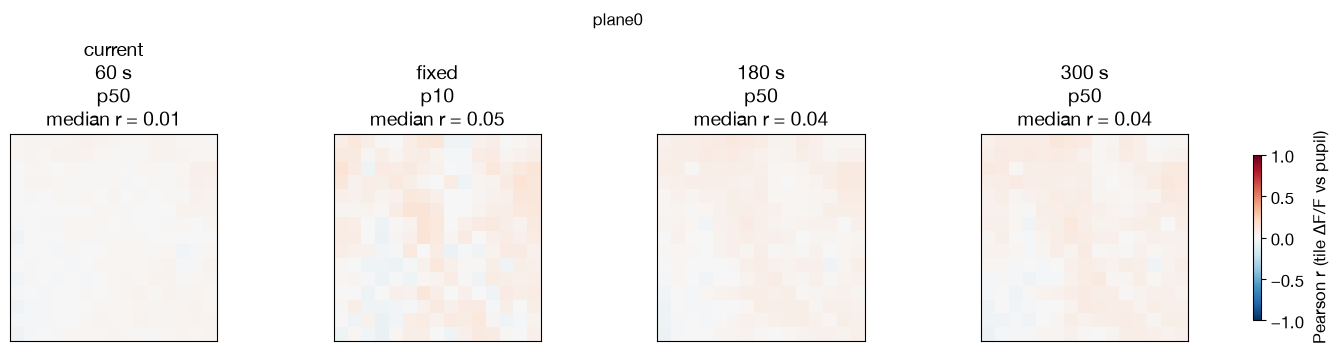

In [ ]:
if b.pupil is None:
    print('No pupil column')
else:
    pupil = np.where(s['valid'], b.pupil, np.nan)
    wf_r = {m: state.lag_correlations(v, pupil, np.array([0]))[0, 0] for m, v in s['wf'].items()}
    display(pd.Series(wf_r, name='whole-FOV r with pupil').round(3).to_frame())
    for t in s['tiles']:
        r = analyses.tile_correlations(t['dff'], np.where(~t['plane'].bad, b.pupil, np.nan))
        fig, axes = plt.subplots(1, len(methods), figsize=(3.6 * len(methods), 3.4), constrained_layout=True, squeeze=False)
        cmap = plt.get_cmap('RdBu_r').copy(); cmap.set_bad('lightgray')
        for ax, m in zip(axes[0], methods):
            im = ax.imshow(analyses.grid_map(r[m], t['plane'].tile_ids, t['plane'].grid_shape), cmap=cmap, vmin=-1, vmax=1)
            ax.set(title=f"{plotting._short(m)}\nmedian r = {np.nanmedian(r[m]):.2f}", xticks=[], yticks=[])
        fig.colorbar(im, ax=axes, label='Pearson r (tile ΔF/F vs pupil)', shrink=0.8)
        fig.suptitle(t['plane'].name); display(fig); plt.close(fig)

## Pupil diameter and derivative: lag curves

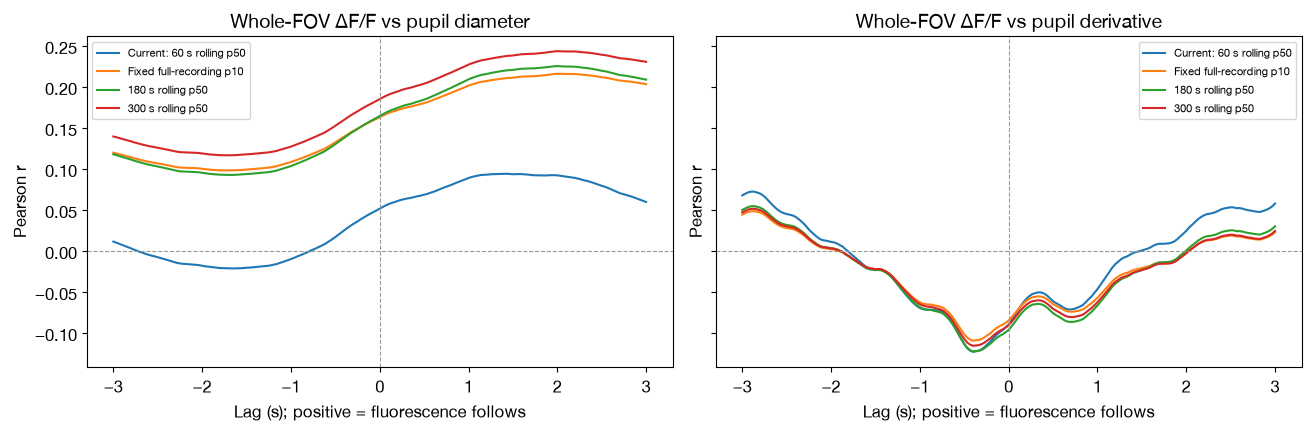

In [ ]:
if b.pupil is not None:
    smooth, deriv = state.smooth_with_derivative(pupil, s['fs'], PUPIL_SMOOTHING_S)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True, constrained_layout=True)
    for ax, (label, x) in zip(axes, [('pupil diameter', smooth), ('pupil derivative', deriv)]):
        lags, curves = analyses.lag_curves(s['wf'], x, s['fs'], MAX_LAG_S)
        ap.plot_lag_curves(lags, curves, ax, title=f'Whole-FOV ΔF/F vs {label}')

## ΔF/F tuning by pupil size

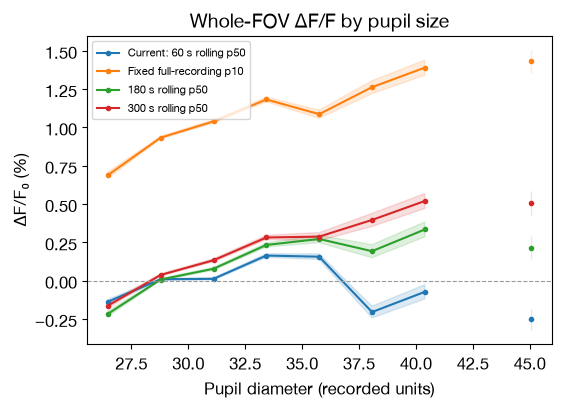

In [ ]:
if b.pupil is not None:
    curves = analyses.tuning_curves(s['wf'], pupil, N_BINS, MIN_BIN_SAMPLES)
    ap.plot_tuning(curves, xlabel='Pupil diameter (recorded units)', title='Whole-FOV ΔF/F by pupil size')

## Locomotion: how much is the animal running?

running 0.0% of frames · 0 bouts · median bout nan s · 0 run onsets


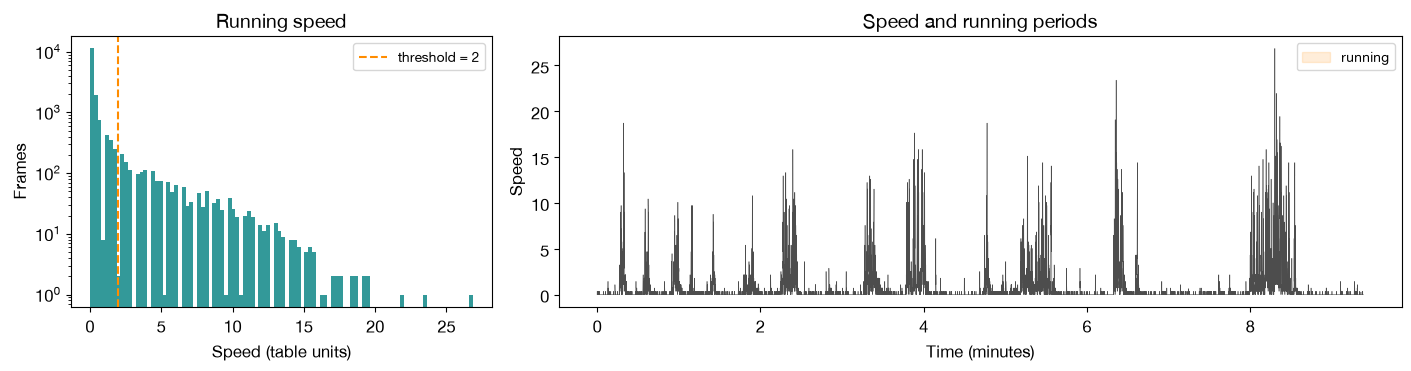

In [ ]:
if b.speed is None:
    print('No running-speed column')
else:
    running = state.running_mask(b.speed, s['fs'], RUNNING_MODEL.threshold, RUNNING_MODEL.min_bout_s)
    on, off = state.state_onsets(running)
    finite = np.isfinite(b.speed)
    bouts = state.bout_durations(running, s['fs'])
    print(f'running {100 * running[finite].mean():.1f}% of frames · {len(bouts)} bouts · '
          f'median bout {np.median(bouts) if len(bouts) else float("nan"):.1f} s · {len(on)} run onsets')
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), constrained_layout=True, gridspec_kw={'width_ratios': [1, 2]})
    ap.plot_speed_distribution(b.speed, RUNNING_MODEL.threshold, axes[0])
    axes[1].plot(s['time_s'] / 60, b.speed, color='0.3', lw=0.4)
    axes[1].fill_between(s['time_s'] / 60, 0, np.nanmax(b.speed), where=running, color='darkorange', alpha=0.15, label='running')
    axes[1].set(xlabel='Time (minutes)', ylabel='Speed', title='Speed and running periods'); axes[1].legend()

## ΔF/F while running vs stationary, and at run onsets

,running_mean_pct,stationary_mean_pct,running_minus_stationary_pp,running_frames,stationary_frames
method,,,,,
Current: 60 s rolling p50,NaN,0.04,NaN,0,16718
Fixed full-recording p10,NaN,1.03,NaN,0,16718
180 s rolling p50,NaN,0.10,NaN,0,16718
300 s rolling p50,NaN,0.14,NaN,0,16718


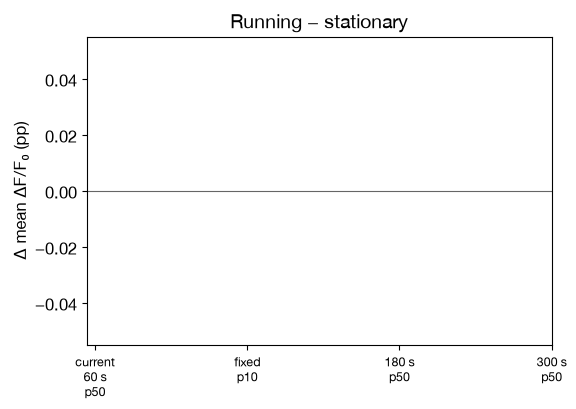

In [ ]:
if b.speed is not None:
    table = state.state_summary(s['wf'], running, s['valid'] & finite)
    display(table.round(2))
    ap.plot_state_difference(table)
    if len(on):
        r = analyses.event_responses(s['wf'], {'Run onset': on, 'Run offset': off}, s['fs'], 5, 10, -5, 0.8)
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
        for ax, ev in zip(axes, r):
            for color, (m, res) in zip(plotting._colors(len(methods)), r[ev].items()):
                ap.plot_event_mean(res['relative_s'], res['centred_mean'], res['centred_sem'], ax, label=m, color=color)
            ax.set_title(f"{ev} · {len(next(iter(r[ev].values()))['onsets'])} transitions · prestimulus-subtracted")
        axes[0].legend(fontsize=8)

## Pupil after regressing out running

For each baseline, a linear model fits ΔF/F from running speed at lags `RUNNING_MODEL.min_lag_s` to `max_lag_s` (in steps of `step_s`; positive = fluorescence follows speed) plus a running/stationary indicator. The fitted running part is then subtracted, keeping the trace's mean, and the pupil analyses above are redone on the residual.

- **Variance explained by running**: in-sample R², plus held-out R² over `cv_folds` contiguous test blocks, with `cv_gap_s` seconds either side excluded from training so lagged regressors can't leak.
- **Kernel**: the fitted speed coefficient at each lag, which shows how ΔF/F follows running in time.
- **Stationary only**: the same pupil analyses on stationary frames, with no model.

**How to read it:** pupil and running are correlated, and regression assigns their shared variance to running. A pupil relationship that survives is the part running doesn't explain linearly at these lags. One that disappears may still be arousal-related, just not separable from locomotion in this recording. Agreement between the regressed and stationary-only results is the more convincing outcome.

,r2_in_sample,r2_held_out,running_indicator_beta_pp,frames_used
method,,,,
Current: 60 s rolling p50,0.190,0.139,0.0,16718
Fixed full-recording p10,0.239,0.128,0.0,16718
180 s rolling p50,0.291,0.271,0.0,16718
300 s rolling p50,0.280,0.223,0.0,16718


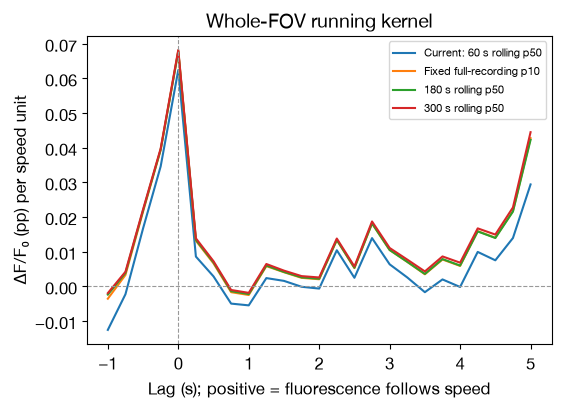

In [ ]:
if b.speed is None:
    raise ValueError('No running-speed column; cannot regress out running')
reg = s['regression'] if s['regress_running'] else session.cached_running_regression(
    s['wf_original'], b.speed, s['fs'], RUNNING_MODEL)
display(reg['table'].round(3))
ap.plot_running_kernels(reg['lags_s'], reg['kernels'], title='Whole-FOV running kernel');

,original,running regressed out,stationary frames only
whole-FOV r with pupil,,,
Current: 60 s rolling p50,0.331,0.052,0.331
Fixed full-recording p10,0.488,0.163,0.488
180 s rolling p50,0.517,0.164,0.517
300 s rolling p50,0.531,0.185,0.531


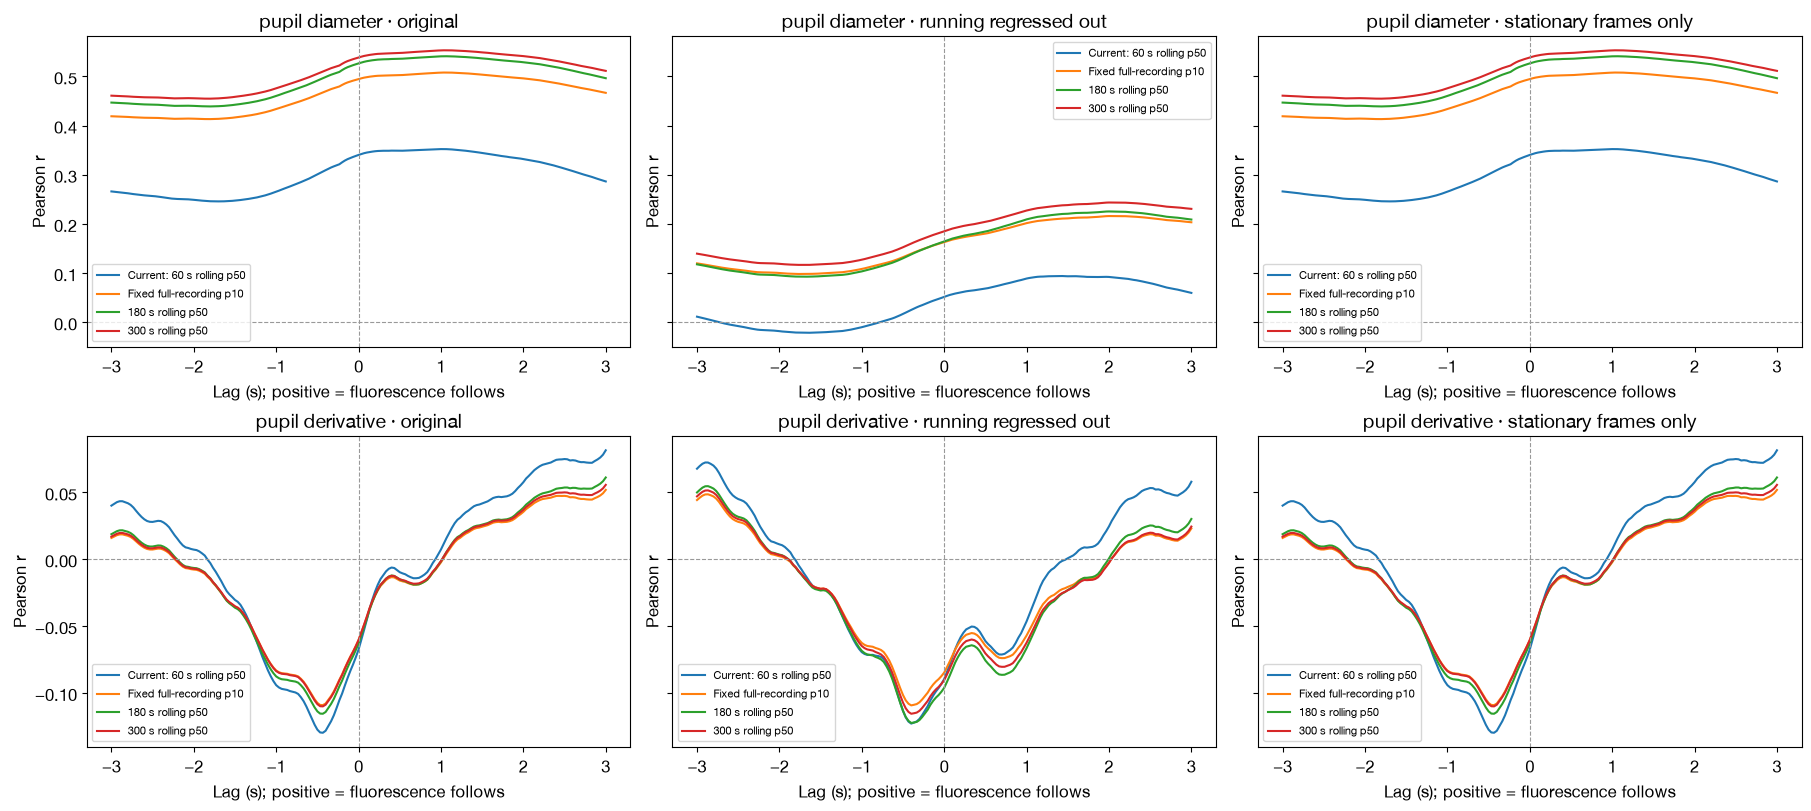

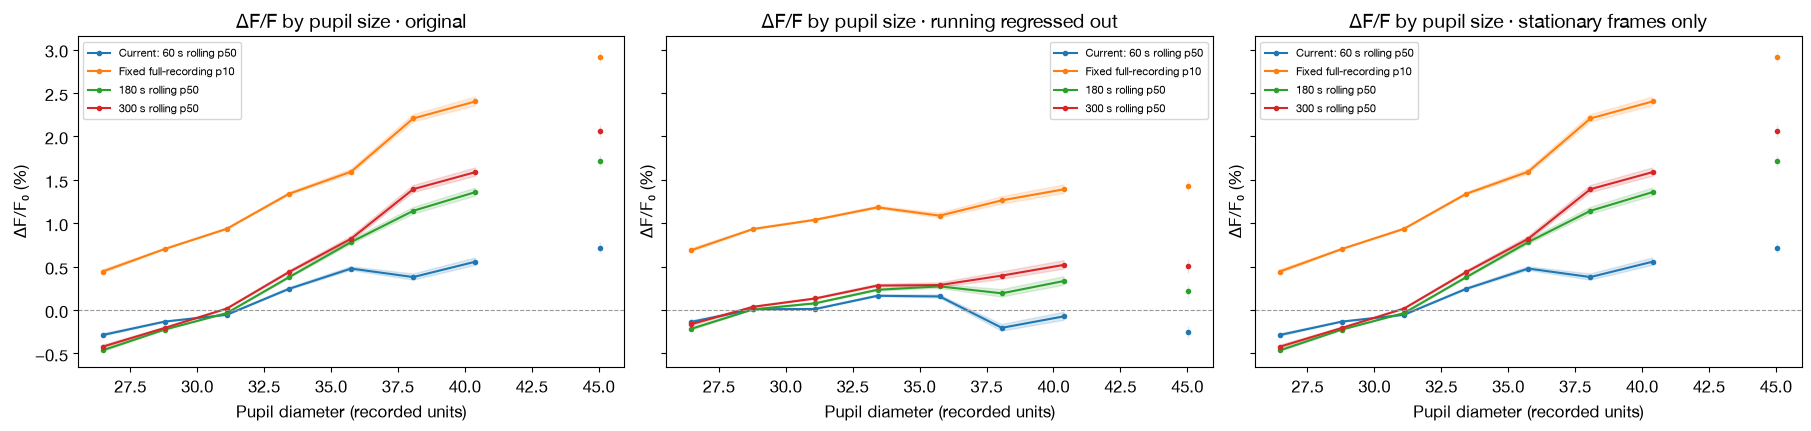

In [ ]:
if b.pupil is not None:
    stationary = ~running & np.isfinite(b.speed)
    versions = {'original': s['wf_original'], 'running regressed out': reg['residual'],
                'stationary frames only': {m: np.where(stationary, v, np.nan) for m, v in s['wf_original'].items()}}
    zero_lag = pd.DataFrame({name: {m: state.lag_correlations(v, pupil, np.array([0]))[0, 0] for m, v in vs.items()}
                             for name, vs in versions.items()})
    display(zero_lag.round(3).rename_axis('whole-FOV r with pupil'))

    fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey='row', constrained_layout=True)
    for j, (name, vs) in enumerate(versions.items()):
        for i, (label, x) in enumerate([('pupil diameter', smooth), ('pupil derivative', deriv)]):
            lags, curves = analyses.lag_curves(vs, x, s['fs'], MAX_LAG_S)
            ap.plot_lag_curves(lags, curves, axes[i, j], title=f'{label} · {name}')
    display(fig); plt.close(fig)

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True, constrained_layout=True)
    for ax, (name, vs) in zip(axes, versions.items()):
        ap.plot_tuning(analyses.tuning_curves(vs, pupil, N_BINS, MIN_BIN_SAMPLES), ax,
                       xlabel='Pupil diameter (recorded units)', title=f'ΔF/F by pupil size · {name}')
    display(fig); plt.close(fig)

,median_tile_r2
method,
Current: 60 s rolling p50,0.016
Fixed full-recording p10,0.024
180 s rolling p50,0.028
300 s rolling p50,0.028


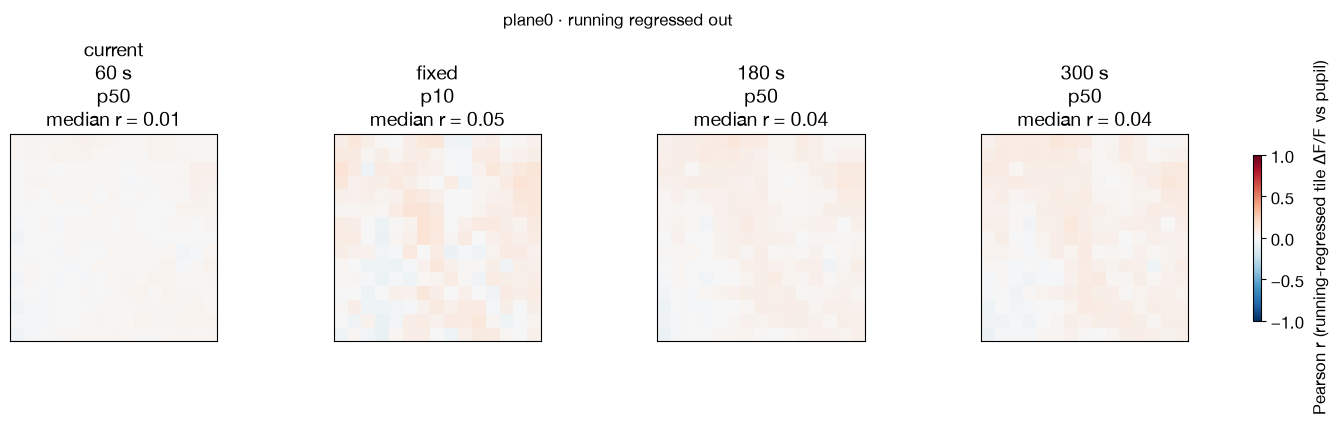

In [ ]:
# Tile-pupil correlation maps after regressing out running (regression fitted per tile)
if b.pupil is not None:
    cmap = plt.get_cmap('RdBu_r').copy(); cmap.set_bad('lightgray')
    for t in s['tiles']:
        tile_reg = t['regression'] if s['regress_running'] else session.cached_running_regression(
            t['dff_original'], b.speed, s['fs'], RUNNING_MODEL)
        display(tile_reg['table'].round(3))
        r = analyses.tile_correlations(tile_reg['residual'], np.where(~t['plane'].bad, b.pupil, np.nan))
        fig, axes = plt.subplots(1, len(methods), figsize=(3.6 * len(methods), 3.4), constrained_layout=True, squeeze=False)
        for ax, m in zip(axes[0], methods):
            im = ax.imshow(analyses.grid_map(r[m], t['plane'].tile_ids, t['plane'].grid_shape), cmap=cmap, vmin=-1, vmax=1)
            ax.set(title=f"{plotting._short(m)}\nmedian r = {np.nanmedian(r[m]):.2f}", xticks=[], yticks=[])
        fig.colorbar(im, ax=axes, label='Pearson r (running-regressed tile ΔF/F vs pupil)', shrink=0.8)
        fig.suptitle(f"{t['plane'].name} · running regressed out"); display(fig); plt.close(fig)